# YOLO 학습 결과 비교 (알약 56클래스, 640px, 20 epoch)

`results.csv` 3개를 불러와서 모델끼리 성능, 학습 속도, 과적합 여부를 비교하는 노트북이에요.

**순서**
1. 데이터 불러오기와 요약표
2. 막대그래프로 성능 비교
3. epoch별 성능 곡선
4. 손실(loss) 곡선과 과적합 확인
5. 아직 더 배울 수 있는지(수렴 여부)
6. 정밀도와 재현율 트레이드오프
7. 학습 시간 대비 성능, 학습률
8. 안정성, 종합 순위, 결론

**용어 정리**
- **Precision(정밀도)**: 모델이 '알약이다'라고 친 박스 중 맞은 비율. 낮으면 엉뚱한 박스를 많이 친다는 뜻이에요.
- **Recall(재현율)**: 실제 알약 중 모델이 찾아낸 비율. 낮으면 놓치는 알약이 많다는 뜻이에요.
- **mAP50**: 박스가 정답과 50% 이상 겹치면 맞은 걸로 치는 종합 점수예요.
- **mAP50-95**: 겹침 기준을 50%부터 95%까지 점점 엄격하게 해서 평균낸 점수예요. 박스를 얼마나 정확히 그리는지까지 봐서 모델 비교의 **핵심 지표**로 써요.
- **F1**: 정밀도와 재현율의 균형 점수예요.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

# csv 파일이 있는 폴더 (노트북과 같은 폴더면 그대로 두세요)
DATA_DIR = Path('.')
# 파일 이름 -> 그래프에 표시할 모델 이름
# 어떤 파일이 어떤 모델인지 확인되면 오른쪽 이름만 바꾸면 모든 그래프에 반영돼요
MODELS = {
    '../YacssoK/outputs/1027_sun_yolo26s_v0_img640/yolo_run/results.csv': 'Model 1 (YOLO26S)',
   '../YacssoK/outputs/1027_sun_yolo11s_v0_img640/yolo_run/results.csv': 'Model 3 (YOLO11S) ',
    '../YacssoK/outputs/1026_modelA_yolov8s_v0_img640/yolo_run/results.csv': 'Model 2 (YOLO8S)',
}
COLORS = ['#2a78d6', '#eb6834', '#1baf7a']

plt.rcParams.update({
    'figure.dpi': 110,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.color': '#e1e0d9',
    'grid.linewidth': 0.6,
    'axes.edgecolor': '#c3c2b7',
    'axes.labelcolor': '#52514e',
    'xtick.color': '#898781',
    'ytick.color': '#898781',
    'axes.titleweight': 'bold',
    'axes.titlesize': 11,
    'lines.linewidth': 2,
    'legend.frameon': False,
})

## 1. 데이터 불러오기

YOLOv8/YOLO11은 세 번째 손실이 `dfl_loss`, YOLO26은 `l1_loss`라서 이름이 달라요. 비교하기 쉽게 `third_loss`로 통일해요.

In [4]:
METRIC_COLS = {
    'metrics/precision(B)': 'precision',
    'metrics/recall(B)': 'recall',
    'metrics/mAP50(B)': 'mAP50',
    'metrics/mAP50-95(B)': 'mAP50_95',
}

dfs, THIRD = {}, {}
for fname, name in MODELS.items():
    df = pd.read_csv(DATA_DIR / fname)
    df.columns = df.columns.str.strip()
    df = df.rename(columns=METRIC_COLS)
    third = 'dfl' if 'train/dfl_loss' in df.columns else 'l1'
    df = df.rename(columns={f'train/{third}_loss': 'train/third_loss',
                            f'val/{third}_loss': 'val/third_loss'})
    df['f1'] = 2 * df['precision'] * df['recall'] / (df['precision'] + df['recall'])
    df['minutes'] = df['time'] / 60                      # time은 누적 초
    df['sec_per_epoch'] = df['time'].diff().fillna(df['time'])
    dfs[name] = df
    THIRD[name] = third
    print(f'{name}: {len(df)} epoch, 세 번째 손실 = {third}_loss')

NAMES = list(dfs)
COLOR = dict(zip(NAMES, COLORS))

Model 1 (YOLO26S): 20 epoch, 세 번째 손실 = l1_loss
Model 2 (YOLO8S) : 20 epoch, 세 번째 손실 = dfl_loss
Model 3 (YOLO11S): 20 epoch, 세 번째 손실 = dfl_loss


## 2. 요약표

모델마다 **mAP50-95가 가장 높았던 epoch(best epoch)** 기준으로 정리했어요. ultralytics가 저장하는 `best.pt`도 이 epoch 근처예요.

- `mAP50-95 gain (last 5 ep)`: 마지막 5 epoch 동안 오른 점수. 크면 아직 배우는 중이에요.
- `epoch to 0.8 / 0.9`: mAP50-95가 처음 0.8, 0.9를 넘은 epoch. 작을수록 빨리 배워요.

In [5]:
def first_epoch_reaching(df, th):
    hit = df.loc[df['mAP50_95'] >= th, 'epoch']
    return int(hit.min()) if len(hit) else np.nan

rows = []
for name, df in dfs.items():
    best = df.loc[df['mAP50_95'].idxmax()]
    last = df.iloc[-1]
    rows.append({
        'model': name,
        'best epoch': int(best['epoch']),
        'best mAP50-95': best['mAP50_95'],
        'mAP50': best['mAP50'],
        'precision': best['precision'],
        'recall': best['recall'],
        'F1': best['f1'],
        'total time (min)': last['minutes'],
        'sec / epoch': last['time'] / len(df),
        'mAP50-95 gain (last 5 ep)': last['mAP50_95'] - df['mAP50_95'].iloc[-6],
        'epoch to 0.8': first_epoch_reaching(df, 0.8),
        'epoch to 0.9': first_epoch_reaching(df, 0.9),
    })
summary = pd.DataFrame(rows).set_index('model')
display(summary.round(3))

,best epoch,best mAP50-95,mAP50,precision,recall,F1,total time (min),sec / epoch,mAP50-95 gain (last 5 ep),epoch to 0.8,epoch to 0.9
model,,,,,,,,,,,
Model 1 (YOLO26S),20,0.940,0.975,0.725,0.988,0.836,12.382,37.145,0.041,11,14
Model 2 (YOLO8S),20,0.954,0.976,0.795,0.989,0.881,11.342,34.027,0.026,11,13
Model 3 (YOLO11S),20,0.935,0.965,0.870,0.866,0.868,12.986,38.958,0.055,12,19


## 3. 막대그래프 성능 비교

### 3-1. best epoch 기준 지표 한눈에 보기
막대가 높을수록 좋아요. mAP50-95가 가장 중요한 지표예요.

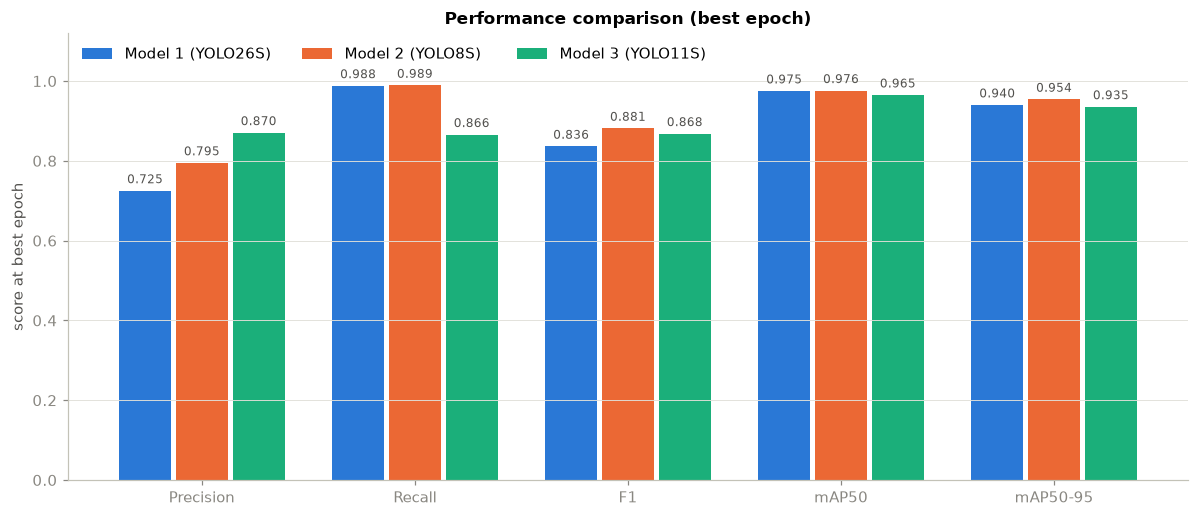

In [6]:
def label_bars(ax, bars, fmt='{:.3f}'):
    for b in bars:
        h = b.get_height()
        if np.isfinite(h):
            ax.annotate(fmt.format(h), (b.get_x() + b.get_width() / 2, h),
                        xytext=(0, 3), textcoords='offset points',
                        ha='center', va='bottom', fontsize=8, color='#52514e')

def offsets(n, w):
    return [(i - (n - 1) / 2) * w for i in range(n)]

metrics = ['precision', 'recall', 'F1', 'mAP50', 'best mAP50-95']
labels = ['Precision', 'Recall', 'F1', 'mAP50', 'mAP50-95']
x = np.arange(len(metrics))
w = 0.8 / len(NAMES)

fig, ax = plt.subplots(figsize=(11, 4.8))
for off, name in zip(offsets(len(NAMES), w), NAMES):
    bars = ax.bar(x + off, summary.loc[name, metrics].astype(float), width=w * 0.92,
                  color=COLOR[name], label=name)
    label_bars(ax, bars)
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylim(0, 1.12)
ax.set_ylabel('score at best epoch')
ax.set_title('Performance comparison (best epoch)')
ax.legend(loc='upper left', ncol=len(NAMES))
ax.grid(axis='x', visible=False)
plt.tight_layout()
plt.show()

### 3-2. 최고 점수, 학습 시간, epoch당 시간
점수는 높을수록, 시간은 낮을수록 좋아요.

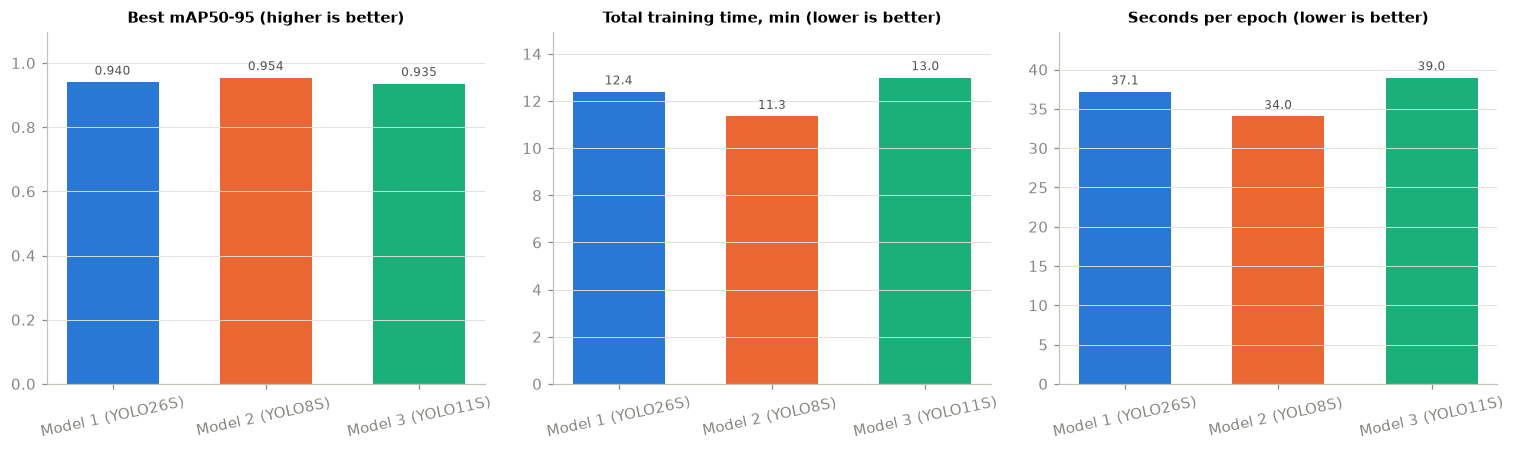

In [7]:
items = [
    ('best mAP50-95', 'Best mAP50-95 (higher is better)', '{:.3f}'),
    ('total time (min)', 'Total training time, min (lower is better)', '{:.1f}'),
    ('sec / epoch', 'Seconds per epoch (lower is better)', '{:.1f}'),
]
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, (col, title, fmt) in zip(axes, items):
    vals = summary[col].astype(float)
    bars = ax.bar(range(len(NAMES)), vals, color=[COLOR[n] for n in NAMES], width=0.6)
    label_bars(ax, bars, fmt)
    ax.set_xticks(range(len(NAMES)))
    ax.set_xticklabels(NAMES, rotation=12)
    ax.set_title(title, fontsize=10)
    ax.set_ylim(0, vals.max() * 1.15)
    ax.grid(axis='x', visible=False)
plt.tight_layout()
plt.show()

### 3-3. 학습 속도: 목표 점수에 몇 epoch 만에 도달했나
막대가 낮을수록 빨리 배우는 모델이에요. 막대가 없으면 20 epoch 안에 도달하지 못한 거예요.

,Model 1 (YOLO26S),Model 2 (YOLO8S),Model 3 (YOLO11S)
mAP50-95 >= 0.5,6,8,8
mAP50-95 >= 0.7,8,10,10
mAP50-95 >= 0.8,11,11,12
mAP50-95 >= 0.9,14,13,19


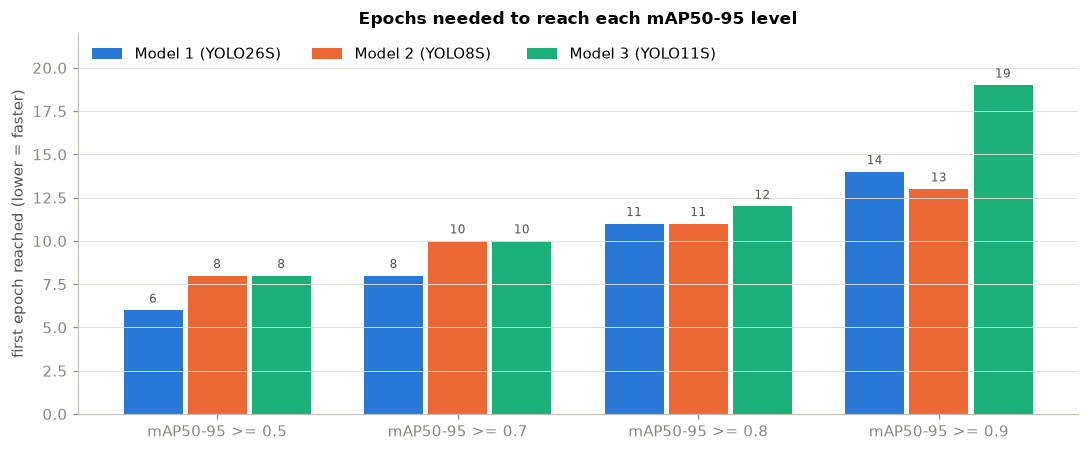

In [8]:
ths = [0.5, 0.7, 0.8, 0.9]
reach = pd.DataFrame({name: [first_epoch_reaching(df, t) for t in ths] for name, df in dfs.items()},
                     index=[f'mAP50-95 >= {t}' for t in ths])
display(reach)

x = np.arange(len(ths))
fig, ax = plt.subplots(figsize=(10, 4.2))
for off, name in zip(offsets(len(NAMES), w), NAMES):
    bars = ax.bar(x + off, reach[name].astype(float), width=w * 0.92, color=COLOR[name], label=name)
    label_bars(ax, bars, '{:.0f}')
ax.set_xticks(x)
ax.set_xticklabels(reach.index)
ax.set_ylabel('first epoch reached (lower = faster)')
ax.set_title('Epochs needed to reach each mAP50-95 level')
ax.set_ylim(0, 22)
ax.legend(loc='upper left', ncol=len(NAMES))
ax.grid(axis='x', visible=False)
plt.tight_layout()
plt.show()

## 4. epoch별 성능 곡선

동그라미는 각 모델이 그 지표에서 가장 높았던 epoch이에요. 곡선이 끝까지 올라가고 있으면 아직 더 배울 여지가 있다는 뜻이에요.

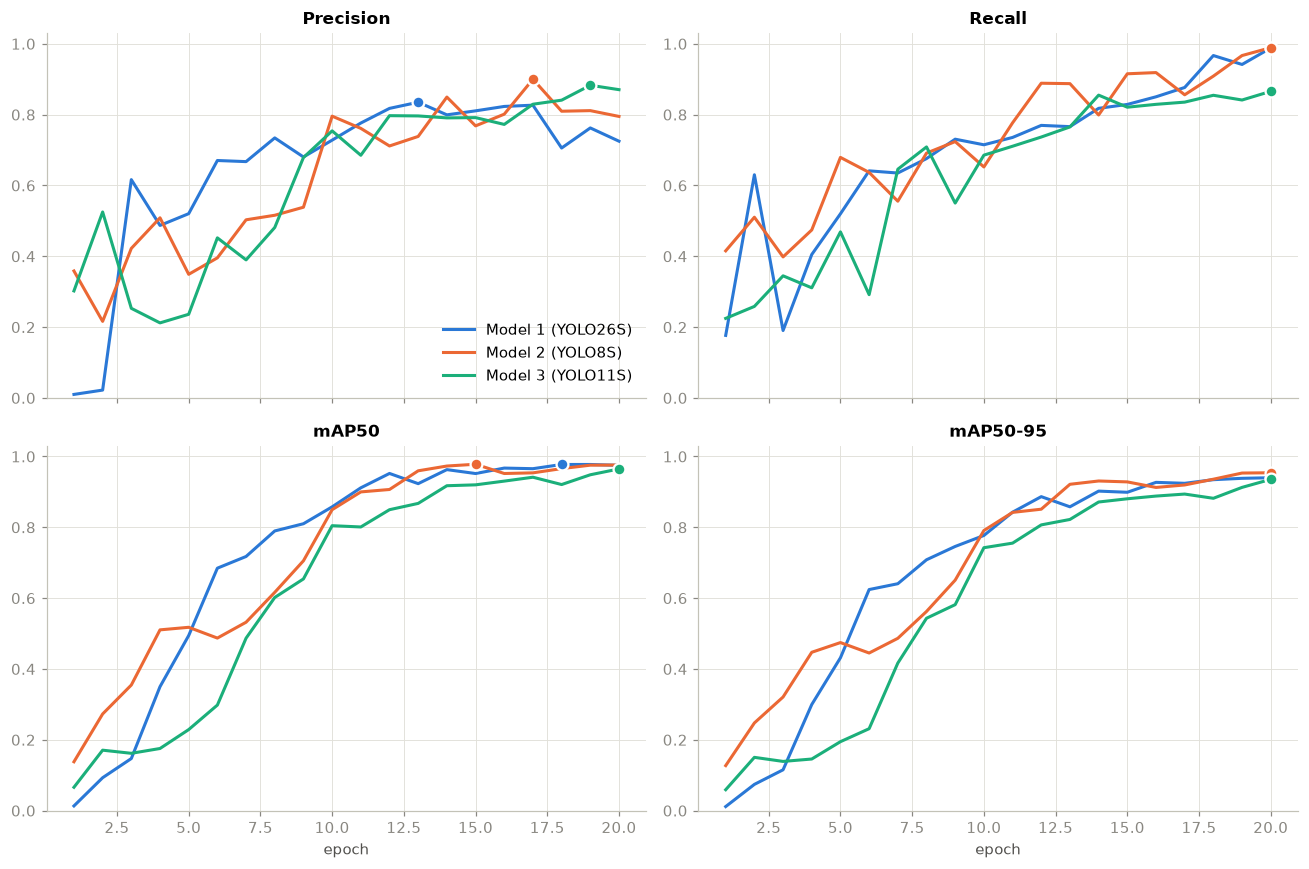

In [9]:
panels = [('precision', 'Precision'), ('recall', 'Recall'),
          ('mAP50', 'mAP50'), ('mAP50_95', 'mAP50-95')]
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)
for ax, (col, title) in zip(axes.flat, panels):
    for name, df in dfs.items():
        ax.plot(df['epoch'], df[col], color=COLOR[name], label=name)
        i = df[col].idxmax()
        ax.scatter(df.loc[i, 'epoch'], df.loc[i, col], s=60, color=COLOR[name],
                   edgecolor='white', linewidth=1.5, zorder=3)
    ax.set_title(title)
    ax.set_ylim(0, 1.03)
for ax in axes[1]:
    ax.set_xlabel('epoch')
axes[0, 0].legend(loc='lower right')
plt.tight_layout()
plt.show()

## 5. 손실(loss) 곡선

손실은 **틀린 정도**라서 낮을수록 좋아요.
- **box loss**: 박스 위치를 얼마나 틀렸는지
- **cls loss**: 알약 종류를 얼마나 틀렸는지 (초반에 값이 크게 튀어서 세로축을 로그 스케일로 그렸어요)
- **dfl / l1 loss**: 박스 경계를 다듬는 보조 손실. YOLO26(l1)과 나머지(dfl)는 계산 방식이 달라서 **값 크기를 서로 비교하면 안 되고**, 각자 줄어드는 모양만 보세요.

윗줄은 학습 데이터(train), 아랫줄은 검증 데이터(val)예요.

In [ ]:
loss_parts = [('box', 'Box loss'), ('cls', 'Cls loss (log scale)'), ('third', 'DFL / L1 loss (not comparable)')]
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5), sharex=True)
for r, split in enumerate(['train', 'val']):
    for c, (part, title) in enumerate(loss_parts):
        ax = axes[r, c]
        for name, df in dfs.items():
            lbl = name if part != 'third' else f'{name} ({THIRD[name]})'
            ax.plot(df['epoch'], df[f'{split}/{part}_loss'], color=COLOR[name], label=lbl)
        ax.set_title(f'{split}: {title}', fontsize=10)
        if part == 'cls':
            ax.set_yscale('log')
        if r == 1:
            ax.set_xlabel('epoch')
axes[0, 0].legend()
axes[0, 2].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 6. 과적합 확인

**과적합**은 학습 데이터만 외워서 새 데이터에서는 못 맞히는 상태예요. 신호는 두 가지예요.
1. 학습 손실은 계속 줄어드는데 **검증 손실이 다시 올라감**
2. 검증 손실과 학습 손실의 **차이(gap)가 점점 벌어짐**

워밍업 구간(1~3 epoch)은 값이 크게 튀어서 4 epoch부터 그렸어요.

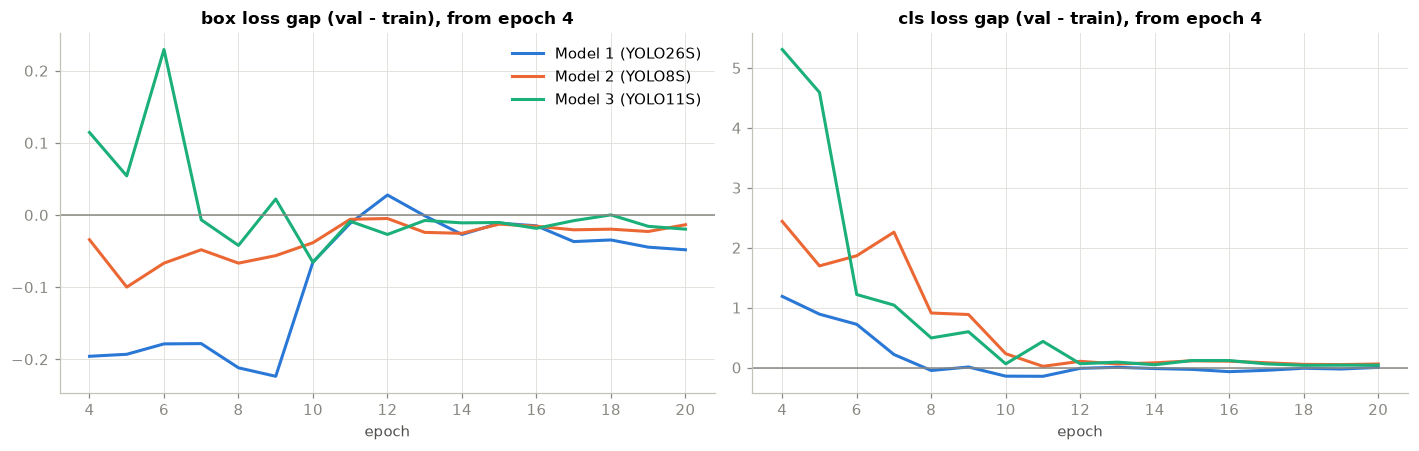

마지막 5 epoch 검증 손실 추세 (epoch당 변화량, 음수면 아직 줄어드는 중)
  Model 1 (YOLO26S): box -0.0206, cls -0.0307, 검증 손실 최저 epoch = 20 -> 과적합 신호 없음 (검증 손실이 아직 줄어드는 중)
  Model 2 (YOLO8S) : box -0.0070, cls -0.0403, 검증 손실 최저 epoch = 20 -> 과적합 신호 없음 (검증 손실이 아직 줄어드는 중)
  Model 3 (YOLO11S): box -0.0095, cls -0.0508, 검증 손실 최저 epoch = 20 -> 과적합 신호 없음 (검증 손실이 아직 줄어드는 중)


In [10]:
START = 4
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, part in zip(axes, ['box', 'cls']):
    for name, df in dfs.items():
        d = df[df['epoch'] >= START]
        ax.plot(d['epoch'], d[f'val/{part}_loss'] - d[f'train/{part}_loss'], color=COLOR[name], label=name)
    ax.axhline(0, color='#898781', lw=1)
    ax.set_title(f'{part} loss gap (val - train), from epoch {START}')
    ax.set_xlabel('epoch')
axes[0].legend()
plt.tight_layout()
plt.show()

print('마지막 5 epoch 검증 손실 추세 (epoch당 변화량, 음수면 아직 줄어드는 중)')
for name, df in dfs.items():
    tail = df.tail(5)
    s_box = np.polyfit(tail['epoch'], tail['val/box_loss'], 1)[0]
    s_cls = np.polyfit(tail['epoch'], tail['val/cls_loss'], 1)[0]
    best_val = int(df.loc[(df['val/box_loss'] + df['val/cls_loss']).idxmin(), 'epoch'])
    ok = s_box < 0 and s_cls < 0
    verdict = '과적합 신호 없음 (검증 손실이 아직 줄어드는 중)' if ok else '과적합 의심 (검증 손실이 다시 오르는 중)'
    print(f'  {name}: box {s_box:+.4f}, cls {s_cls:+.4f}, 검증 손실 최저 epoch = {best_val} -> {verdict}')

## 7. 아직 더 배울 수 있나? (수렴 여부)

왼쪽은 epoch마다 mAP50-95가 얼마나 올랐는지(3 epoch 이동평균), 오른쪽은 마지막 5 epoch의 평균 상승 속도예요.
상승 속도가 0보다 확실히 크면 **20 epoch로는 아직 덜 배운 상태**라 epoch를 늘리면 점수가 더 오를 가능성이 커요.

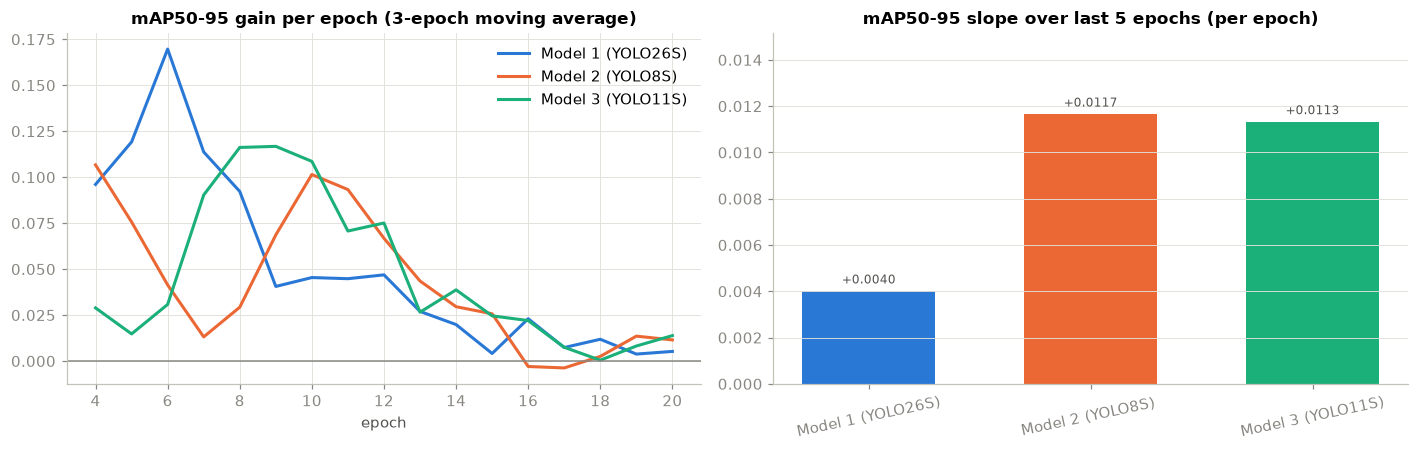

Model 1 (YOLO26S): best epoch 20/20, 최근 상승 속도 +0.0040/epoch -> 마지막 epoch이 최고점이라 아직 수렴 전
Model 2 (YOLO8S) : best epoch 20/20, 최근 상승 속도 +0.0117/epoch -> 마지막 epoch이 최고점이라 아직 수렴 전
Model 3 (YOLO11S): best epoch 20/20, 최근 상승 속도 +0.0113/epoch -> 마지막 epoch이 최고점이라 아직 수렴 전


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for name, df in dfs.items():
    gain = df['mAP50_95'].diff().rolling(3).mean()
    axes[0].plot(df['epoch'], gain, color=COLOR[name], label=name)
axes[0].axhline(0, color='#898781', lw=1)
axes[0].set_title('mAP50-95 gain per epoch (3-epoch moving average)')
axes[0].set_xlabel('epoch')
axes[0].legend()

slopes = {name: np.polyfit(df.tail(5)['epoch'], df.tail(5)['mAP50_95'], 1)[0] for name, df in dfs.items()}
bars = axes[1].bar(range(len(NAMES)), [slopes[n] for n in NAMES], color=[COLOR[n] for n in NAMES], width=0.6)
label_bars(axes[1], bars, '{:+.4f}')
axes[1].set_xticks(range(len(NAMES)))
axes[1].set_xticklabels(NAMES, rotation=12)
axes[1].set_title('mAP50-95 slope over last 5 epochs (per epoch)')
axes[1].set_ylim(0, max(slopes.values()) * 1.3)
axes[1].grid(axis='x', visible=False)
plt.tight_layout()
plt.show()

for name in NAMES:
    best_ep = summary.loc[name, 'best epoch']
    still = best_ep == len(dfs[name])
    print(f'{name}: best epoch {best_ep}/{len(dfs[name])}, 최근 상승 속도 {slopes[name]:+.4f}/epoch'
          + (' -> 마지막 epoch이 최고점이라 아직 수렴 전' if still else ''))

## 8. 정밀도와 재현율 트레이드오프

**왼쪽 그래프**: 점 하나가 epoch 하나예요. 학습이 진행될수록 오른쪽 위(둘 다 높음)로 가면 좋아요. 회색 점선은 F1이 같은 선이에요. 큰 점이 마지막 epoch이에요.

**오른쪽 그래프**: 정밀도 - 재현율.
- 0보다 위: 확실할 때만 박스를 침 (놓치는 알약이 생길 수 있음)
- 0보다 아래: 알약은 거의 다 찾지만 엉뚱한 박스도 많이 침

참고로 mAP는 모든 확신도 기준을 다 따져서 계산하기 때문에 이 트레이드오프의 영향을 덜 받아요. 정밀도와 재현율은 실제 사용할 때 확신도 기준(conf)을 바꾸면 조절할 수 있어요.

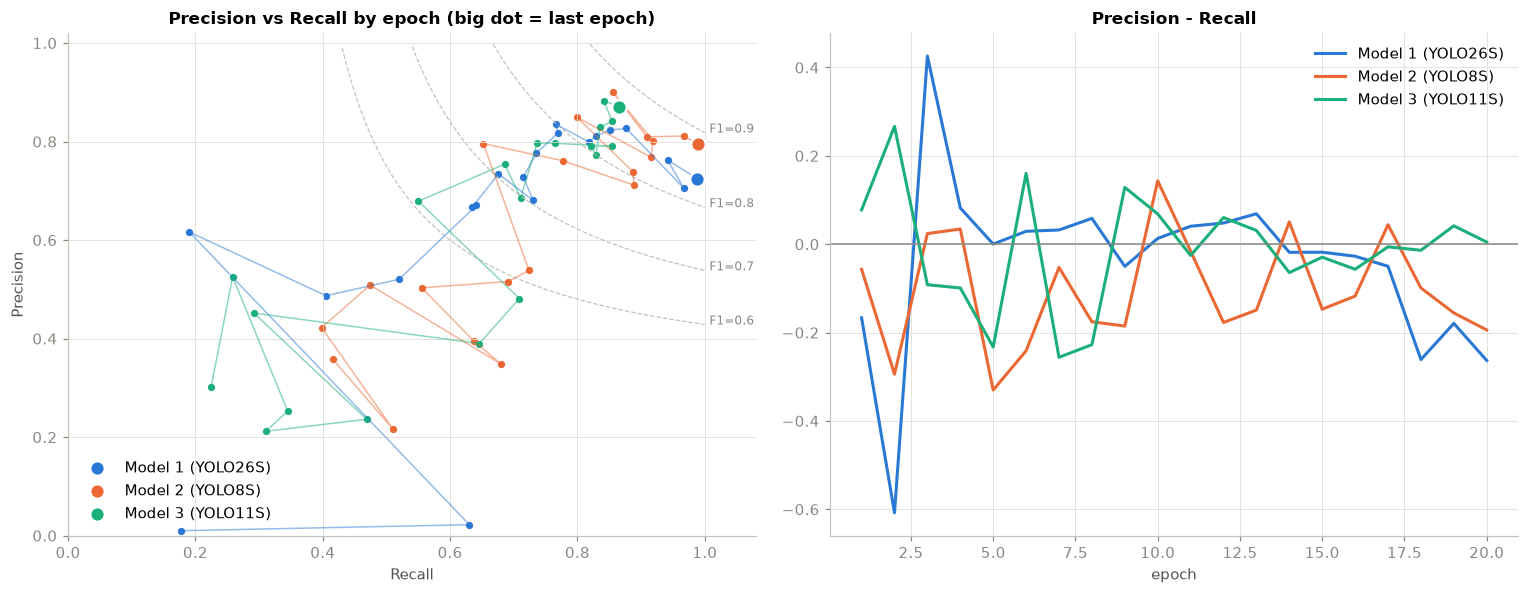

Model 1 (YOLO26S): precision 0.725, recall 0.988 -> 재현율 쪽으로 치우침 (엉뚱한 박스가 많음)
Model 2 (YOLO8S) : precision 0.795, recall 0.989 -> 재현율 쪽으로 치우침 (엉뚱한 박스가 많음)
Model 3 (YOLO11S): precision 0.870, recall 0.866 -> 균형


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
ax = axes[0]
for f in [0.6, 0.7, 0.8, 0.9]:
    r = np.linspace(f / 2 + 0.005, 1, 300)
    p = f * r / (2 * r - f)
    m = (p <= 1.0) & (p >= 0)
    ax.plot(r[m], p[m], ls='--', lw=0.8, color='#c3c2b7')
    ax.annotate(f'F1={f}', (1.0, f / (2 - f)), fontsize=8, color='#898781', xytext=(3, 0), textcoords='offset points')
for name, df in dfs.items():
    ax.plot(df['recall'], df['precision'], color=COLOR[name], lw=1, alpha=0.5)
    ax.scatter(df['recall'], df['precision'], color=COLOR[name], s=14)
    last = df.iloc[-1]
    ax.scatter(last['recall'], last['precision'], color=COLOR[name], s=90, edgecolor='white', linewidth=1.5, zorder=3, label=name)
ax.set_xlim(0, 1.08)
ax.set_ylim(0, 1.02)
ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_title('Precision vs Recall by epoch (big dot = last epoch)')
ax.legend(loc='lower left')

ax = axes[1]
for name, df in dfs.items():
    ax.plot(df['epoch'], df['precision'] - df['recall'], color=COLOR[name], label=name)
ax.axhline(0, color='#898781', lw=1)
ax.set_title('Precision - Recall')
ax.set_xlabel('epoch')
ax.legend()
plt.tight_layout()
plt.show()

for name in NAMES:
    p, r = summary.loc[name, 'precision'], summary.loc[name, 'recall']
    kind = '균형' if abs(p - r) < 0.05 else ('재현율 쪽으로 치우침 (엉뚱한 박스가 많음)' if r > p else '정밀도 쪽으로 치우침 (놓치는 알약이 있음)')
    print(f'{name}: precision {p:.3f}, recall {r:.3f} -> {kind}')

## 9. 학습 시간 대비 성능, 학습률

**왼쪽**: 가로축이 실제 걸린 시간(분)이에요. 같은 시간에 더 위에 있는 모델이 효율이 좋아요.
**가운데**: epoch마다 걸린 시간이에요. 특정 epoch에서 튀면 그때 컴퓨터(GPU) 상태나 다른 작업 영향일 수 있어요.
**오른쪽**: 학습률(learning rate). 처음 3 epoch은 워밍업이라 값이 변하고, 그 뒤로 점점 줄어들어요. 세 모델 모두 설정이 같아서 하나만 그렸어요. 초반 1~3 epoch에 손실이 튀는 건 이 워밍업 때문이라 정상이에요.

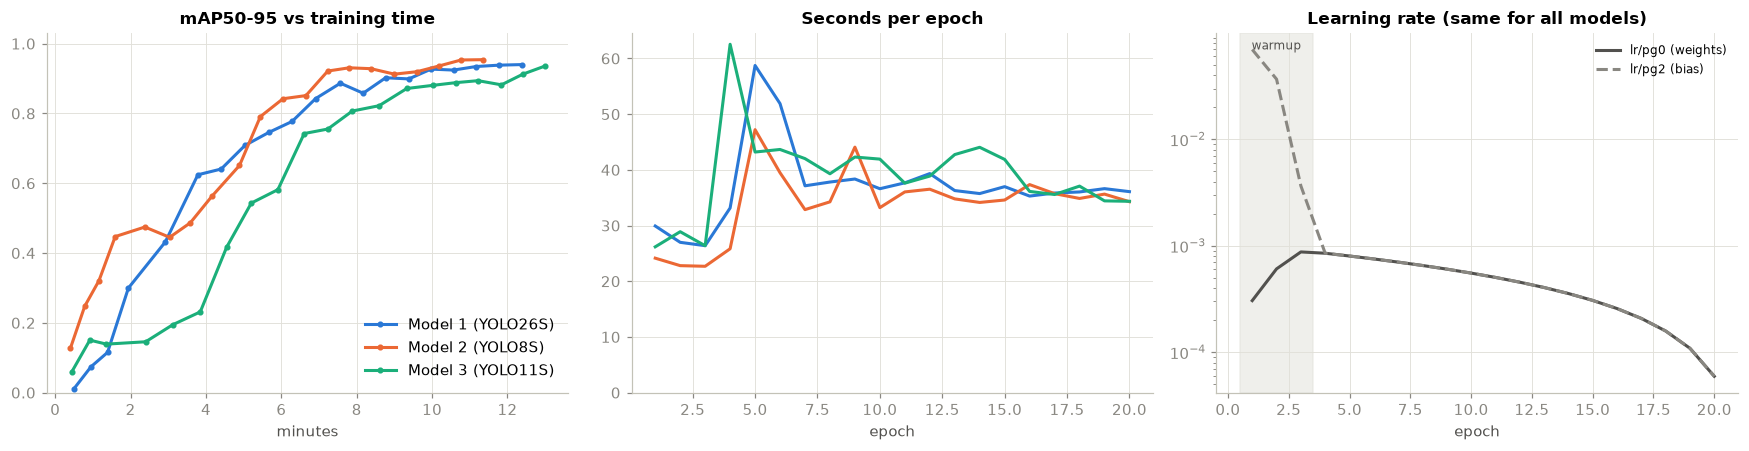

1분당 얻은 mAP50-95 (높을수록 효율적):
  Model 2 (YOLO8S) : 0.0841
  Model 1 (YOLO26S): 0.0759
  Model 3 (YOLO11S): 0.0720


In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for name, df in dfs.items():
    axes[0].plot(df['minutes'], df['mAP50_95'], color=COLOR[name], label=name, marker='o', ms=3)
    axes[1].plot(df['epoch'], df['sec_per_epoch'], color=COLOR[name], label=name)
axes[0].set_title('mAP50-95 vs training time')
axes[0].set_xlabel('minutes')
axes[0].set_ylim(0, 1.03)
axes[0].legend(loc='lower right')
axes[1].set_title('Seconds per epoch')
axes[1].set_xlabel('epoch')
axes[1].set_ylim(0, None)

df0 = dfs[NAMES[0]]
axes[2].plot(df0['epoch'], df0['lr/pg0'], color='#52514e', label='lr/pg0 (weights)')
axes[2].plot(df0['epoch'], df0['lr/pg2'], color='#898781', ls='--', label='lr/pg2 (bias)')
axes[2].set_yscale('log')
axes[2].axvspan(0.5, 3.5, color='#e1e0d9', alpha=0.5)
axes[2].annotate('warmup', (2, df0['lr/pg2'].max()), ha='center', fontsize=8, color='#52514e')
axes[2].set_title('Learning rate (same for all models)')
axes[2].set_xlabel('epoch')
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()

eff = (summary['best mAP50-95'] / summary['total time (min)']).sort_values(ascending=False)
print('1분당 얻은 mAP50-95 (높을수록 효율적):')
for n, v in eff.items():
    print(f'  {n}: {v:.4f}')

## 10. 안정성

점수가 epoch마다 꾸준히 오르는지, 오르락내리락하는지 봐요. 떨어진 횟수가 적고 최대 하락폭이 작을수록 안정적이에요. 후반(11 epoch 이후)에도 자주 떨어지면 검증 데이터가 적어서 점수가 흔들리는 걸 수 있어요.

,drops (all),drops (after ep10),max drop,std of change (after ep10)
model,,,,
Model 1 (YOLO26S),3,3,-0.0287,0.0285
Model 2 (YOLO8S),3,2,-0.0295,0.0257
Model 3 (YOLO11S),2,1,-0.0119,0.0198


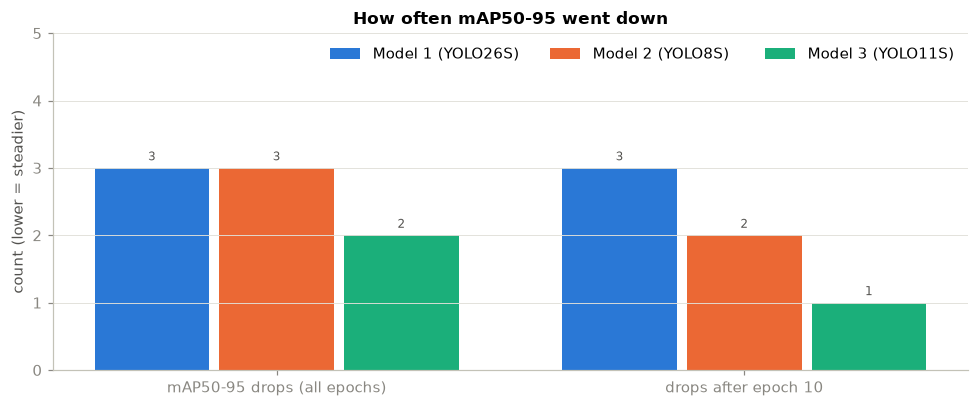

In [15]:
rows = []
for name, df in dfs.items():
    d = df['mAP50_95'].diff()
    late = d[df['epoch'] > 10]
    rows.append({'model': name,
                 'drops (all)': int((d < 0).sum()),
                 'drops (after ep10)': int((late < 0).sum()),
                 'max drop': d.min(),
                 'std of change (after ep10)': late.std()})
stab = pd.DataFrame(rows).set_index('model')
display(stab.round(4))

fig, ax = plt.subplots(figsize=(9, 3.8))
cols = ['drops (all)', 'drops (after ep10)']
x = np.arange(len(cols))
for off, name in zip(offsets(len(NAMES), w), NAMES):
    bars = ax.bar(x + off, stab.loc[name, cols].astype(float), width=w * 0.92, color=COLOR[name], label=name)
    label_bars(ax, bars, '{:.0f}')
ax.set_xticks(x)
ax.set_xticklabels(['mAP50-95 drops (all epochs)', 'drops after epoch 10'])
ax.set_ylabel('count (lower = steadier)')
ax.set_title('How often mAP50-95 went down')
ax.set_ylim(0, stab[cols].values.max() + 2)
ax.legend(ncol=len(NAMES))
ax.grid(axis='x', visible=False)
plt.tight_layout()
plt.show()

## 11. 종합 순위

항목별로 1등부터 순위를 매기고 평균을 냈어요. **평균 순위가 낮을수록** 종합적으로 좋은 모델이에요. 어떤 항목이 더 중요한지는 목적에 따라 다르니 표도 같이 보세요.

,best mAP50-95,mAP50,F1,precision,recall,total time (min),epoch to 0.9,avg rank
model,,,,,,,,
Model 1 (YOLO26S),2.0,2.0,3.0,3.0,2.0,2.0,2.0,2.29
Model 2 (YOLO8S),1.0,1.0,1.0,2.0,1.0,1.0,1.0,1.14
Model 3 (YOLO11S),3.0,3.0,2.0,1.0,3.0,3.0,3.0,2.57


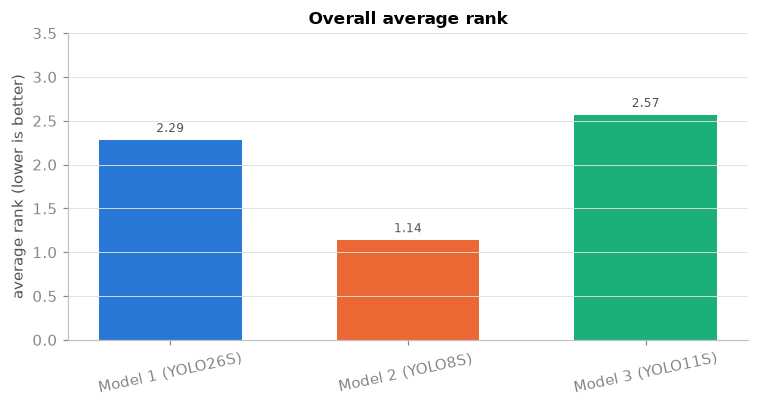

In [16]:
criteria = {                      # True = 낮을수록 좋음
    'best mAP50-95': False,
    'mAP50': False,
    'F1': False,
    'precision': False,
    'recall': False,
    'total time (min)': True,
    'epoch to 0.9': True,
}
ranks = pd.DataFrame({c: summary[c].rank(ascending=asc, method='min') for c, asc in criteria.items()})
ranks['avg rank'] = ranks.mean(axis=1)
display(ranks.round(2))

fig, ax = plt.subplots(figsize=(7, 3.8))
bars = ax.bar(range(len(NAMES)), ranks.loc[NAMES, 'avg rank'], color=[COLOR[n] for n in NAMES], width=0.6)
label_bars(ax, bars, '{:.2f}')
ax.set_xticks(range(len(NAMES)))
ax.set_xticklabels(NAMES, rotation=12)
ax.set_ylabel('average rank (lower is better)')
ax.set_title('Overall average rank')
ax.set_ylim(0, len(NAMES) + 0.5)
ax.grid(axis='x', visible=False)
plt.tight_layout()
plt.show()

## 12. 자동 결론

위 숫자들을 바탕으로 요약 문장을 자동으로 만들어요. 모델 이름을 바꿔도 그대로 맞게 나와요.

In [ ]:
best_model = summary['best mAP50-95'].idxmax()
fastest = summary['total time (min)'].idxmin()
balanced = (summary['precision'] - summary['recall']).abs().idxmin()
gap = summary['best mAP50-95'].max() - summary['best mAP50-95'].min()
not_converged = [n for n in NAMES if summary.loc[n, 'best epoch'] == len(dfs[n])]

print(f'- 정확도(mAP50-95) 1위: {best_model} ({summary.loc[best_model, "best mAP50-95"]:.3f})')
print(f'- 가장 빠른 학습: {fastest} ({summary.loc[fastest, "total time (min)"]:.1f}분)')
print(f'- 정밀도와 재현율이 가장 균형 잡힌 모델: {balanced}')
print(f'- 1위와 꼴찌의 mAP50-95 차이: {gap:.3f}' + (' (작은 차이라 검증 데이터가 적으면 뒤집힐 수 있음)' if gap < 0.03 else ''))
if not_converged:
    print(f'- 마지막 epoch이 최고점인 모델: {", ".join(not_converged)} -> epoch를 늘리면 더 오를 가능성이 큼')
print(f'- 종합 평균 순위 1위: {ranks["avg rank"].idxmin()}')

## 13. 분석 정리 (20 epoch 결과 기준)

**1. 최종 성능은 셋 다 비슷하게 높아요.**
mAP50-95가 Model 3 0.954, Model 1 0.940, Model 2 0.935예요. 차이가 0.02 정도라서 검증 이미지 수가 많지 않으면 다시 학습할 때 순위가 바뀔 수도 있어요.

**2. 세 모델 모두 아직 덜 배웠어요.**
셋 다 20번째 epoch이 최고점이고, 검증 손실도 계속 줄고 있어요. 과적합 신호는 없어요. epoch를 50 이상으로 늘리면 점수가 더 오를 가능성이 커요. 특히 Model 2는 마지막 5 epoch 동안 가장 많이 올라서(+0.055) 가장 덜 수렴한 상태예요.

**3. 정밀도와 재현율 성향이 달라요.**
Model 1과 Model 3은 재현율이 0.99로 알약을 거의 다 찾지만, 정밀도가 0.72~0.79라 엉뚱한 박스도 꽤 쳐요. Model 2는 둘 다 0.87 정도로 균형이 잡혀 있어요. 실제로 쓸 때는 확신도 기준(conf)을 높이면 정밀도를 올릴 수 있어요.

**4. 학습 속도와 시간**
Model 3이 가장 빨라요. 약 11.3분 걸렸고, 13 epoch 만에 mAP50-95 0.9를 넘었어요. Model 2는 약 13분으로 가장 오래 걸렸고, 0.9는 19 epoch에야 넘었어요.

**5. 초반 불안정은 정상이에요.**
1~3 epoch에 검증 cls loss가 크게 튀는 건 학습률 워밍업 구간이라 그래요. 결과에는 문제가 없어요.

**지금 고른다면**: 정확도와 속도 모두 Model 3이 가장 좋아요. 다만 엉뚱한 박스가 적어야 하는 상황이면 Model 2의 균형도 고려할 만해요. 확실히 결정하려면 epoch를 늘려서 다시 비교해 보는 걸 추천해요.